# Simulation and Modeling of Vegetable Market Price Fluctuation

**Course:** Simulation and Modeling Lab (`CSE 413`) — Level 4, Term 1  
**Course Teacher:** Audity Ghosh, Lecturer, Department of CSE, University of Information Technology and Sciences (UITS)  
**Submitted by:** Elham Rafat Mahmud | **Section:** B1  

## 1. Introduction & Variable Taxonomy

Vegetable prices in Bangladeshi retail markets do not stay still. A kilogram of tomato can cost far less in winter than in the monsoon, and a flood, transport strike, or supply disruption can push prices up overnight. Because we cannot run controlled experiments on real agricultural markets, **stochastic simulation** lets us build a synthetic market with known rules, generate years of daily prices, and test statistical methods under controlled conditions.

### 1.1 Statistical Variable Taxonomy (`Introduction to Statistics.pdf`)
Before building the simulation, we classify each variable in the model so that every statistical test matches its measurement scale:

| Variable | Broad Category | Sub-Type & Scale | Role in Simulation & Statistical Testing |
| :--- | :--- | :--- | :--- |
| `Vegetable` (`Tomato`, `Potato`, `Onion`, `Brinjal`) | **Qualitative (Categorical)** | **Nominal** (Unordered categories) | Identifies each crop's base price $B_v$, seasonal amplitude $A_v$, peak day, daily noise $\sigma_v$, and shock sensitivity $k_v$ |
| `Season` (`Winter`, `Summer`, `Monsoon`, `Autumn`) | **Qualitative (Categorical)** | **Nominal** (Cyclic calendar categories with no natural rank order) | Grouping variable for seasonal comparisons (Two-Sample *t*-test and Chi-Square Goodness-of-Fit) |
| `DayOfYear` ($d_t \in \{1,\dots,365\}$) | **Quantitative (Numerical)** | **Discrete / Interval** (Circular calendar position) | Drives deterministic seasonal wave $S_{v,t}$ and 3D cylindrical phase angle $\theta_t = 2\pi d_t / 365$ |
| `ShockStart` ($0/1$ indicator, seasonal count $O_i$) | **Quantitative (Numerical)** | **Discrete / Ratio** (Event count) | Observed shock-arrival frequency $O_i$ in the Chi-Square Goodness-of-Fit test |
| `Price` ($P_{v,t}$ in Tk/kg) & `Basket Cost` (Tk/month) | **Quantitative (Numerical)** | **Continuous / Ratio** (Positive real values) | Primary response variable for descriptive statistics, *t*-tests, and Monte Carlo budget risk |
| `LogReturn` ($r_{v,t} = \ln(P_{v,t}/P_{v,t-1})$) | **Quantitative (Numerical)** | **Continuous / Ratio** (Daily percentage change) | Isolates day-to-day co-movement across crops for correlation and eigenvalue factor analysis |

## 2. Necessary Libraries

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.precision", 2)
print("Libraries loaded successfully.")

Libraries loaded successfully.

## 3. Random Number Foundations (Lab Day 3 Recap)

The whole simulation is driven by pseudorandom numbers, so we first verify that our random number generators behave as theory predicts.

### 3.1 Uniform random numbers
`np.random.rand()` generates numbers uniformly distributed on $[0, 1)$. We use them to decide **whether a supply shock starts on a given day** (an event occurs when the uniform draw falls below that day's shock probability $p_t$).

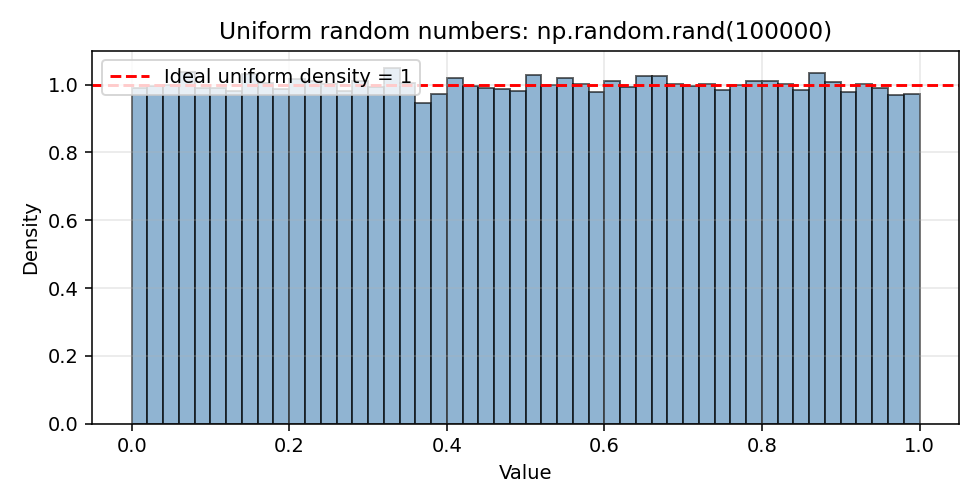

In [2]:
np.random.seed(42)
u = np.random.rand(100000)

plt.figure(figsize=(7, 3.6))
plt.hist(u, bins=50, density=True, alpha=0.6, color="steelblue", edgecolor="black")
plt.axhline(1.0, color="red", linestyle="--", label="Ideal uniform density = 1")
plt.xlabel("Value"); plt.ylabel("Density")
plt.title("Uniform random numbers: np.random.rand(100000)")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### 3.2 Is the generator really uniform? (Chi-square check)
We split `10,000` uniform random numbers into `10` equal bins on $[0, 1)$. Under uniformity, each bin has expected frequency $E_i = 1,000$.
- **$H_0$:** The numbers are uniformly distributed on $[0, 1)$.
- **$H_1$:** They are not uniformly distributed ($\alpha = 0.05$, $df = 10 - 1 = 9$).

In [3]:
np.random.seed(42)
r = np.random.rand(10000)

observed_u, _ = np.histogram(r, bins=10, range=(0, 1))
expected_u = np.full(10, len(r) / 10)

chi_sq_u = np.sum((observed_u - expected_u) ** 2 / expected_u)
df_u = len(observed_u) - 1
critical_u = stats.chi2.ppf(0.95, df_u)
p_val_u = stats.chi2.sf(chi_sq_u, df_u)

print("Observed per bin:", observed_u)
print(f"Chi-square statistic: {chi_sq_u:.2f}")
print(f"Degrees of freedom: {df_u}")
print(f"Critical value (alpha=0.05): {critical_u:.2f}")
print(f"p-value: {p_val_u:.4f}")
print("Reject H0" if chi_sq_u > critical_u else "Fail to reject H0: the generator looks uniform.")

Observed per bin: [1031 1012 1010 1005 1018 1032 1005  925 1001  961]
Chi-square statistic: 9.75
Degrees of freedom: 9
Critical value (alpha=0.05): 16.92
p-value: 0.3711
Fail to reject H0: the generator looks uniform.

### 3.3 Normal random numbers
Day-to-day market noise (small random supply and demand fluctuations) is modeled as normally distributed using `np.random.normal(mean, std, size)`.

Mean = 0.0000, Std = 0.0300

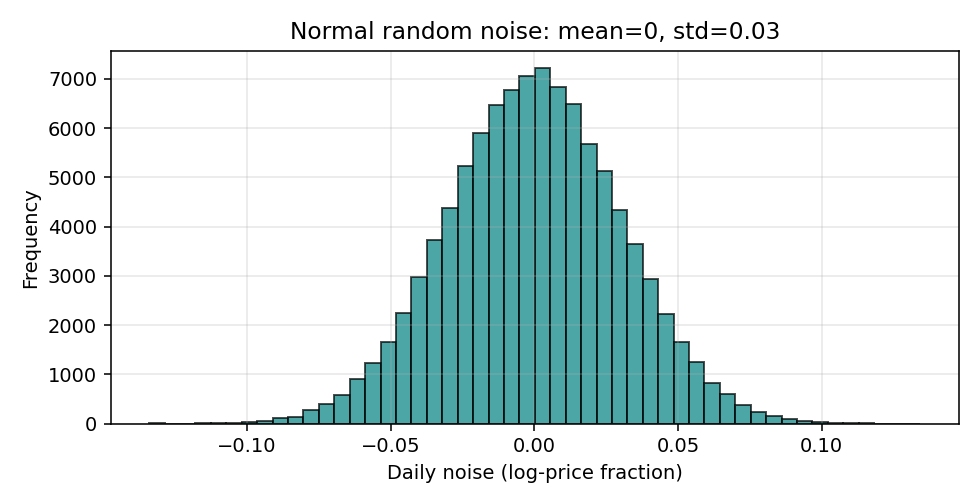

In [4]:
np.random.seed(42)
noise = np.random.normal(0, 0.03, 100000)   # mean 0, std 3% (tomato-like daily noise)
print(f"Mean = {noise.mean():.4f}, Std = {noise.std():.4f}")

plt.figure(figsize=(7, 3.6))
plt.hist(noise, bins=50, edgecolor="black", alpha=0.7, color="teal")
plt.xlabel("Daily noise (log-price fraction)"); plt.ylabel("Frequency")
plt.title("Normal random noise: mean=0, std=0.03")
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### 3.4 Seeds and reproducibility
Setting `np.random.seed(...)` fixes the random sequence so that every run of this notebook produces identical numbers.

### 3.5 Random permutation for sampling without replacement
`np.random.permutation` shuffles day indices so taking the first $k$ indices draws a **random sample without replacement** for our *t*-tests.

In [5]:
np.random.seed(10); a = np.random.randint(1, 51, (3, 3))
np.random.seed(10); b = np.random.randint(1, 51, (3, 3))
np.random.seed(None); c = np.random.randint(1, 51, (3, 3))

print("Seed 10, run 1:\n", a)
print("Seed 10, run 2:\n", b)
print("Same output with the same seed?", np.array_equal(a, b))

np.random.seed(1)
print("Shuffled 1..10:", np.random.permutation(np.arange(1, 11)))

Seed 10, run 1:
 [[10 37 16]
 [ 1 50 29]
 [26 30 49]]
Seed 10, run 2:
 [[10 37 16]
 [ 1 50 29]
 [26 30 49]]
Same output with the same seed? True
Shuffled 1..10: [ 3 10  7  5  1  4  2  8  9  6]

## 4. The Simulation Model

The daily retail price of vegetable $v$ on day $t$ is built from **four multiplicative parts** so that swings scale naturally as percentages and prices can never turn negative:

$$P_{v,t} = B_v \times S_{v,t} \times e^{X_{v,t}} \times \left(1 + k_v \, Z_t\right)$$

| Part | Meaning | How it is generated |
| :--- | :--- | :--- |
| $B_v$ | Base price (Tk/kg) | Fixed baseline assumption per vegetable (`60`, `35`, `70`, `55` Tk/kg) |
| $S_{v,t}$ | Seasonal factor | $1 + A_v \sin\!\left(\frac{2\pi (d_t - \text{peak}_v + 91.25)}{365}\right)$, peaking on day $d_t = \text{peak}_v$ |
| $X_{v,t}$ | Persistent daily market noise | $X_{v,t} = 0.90\,X_{v,t-1} + \varepsilon_{v,t}$ with $\varepsilon_{v,t} \sim \mathcal{N}(0, \sigma_v^2)$ so daily moves persist across days |
| $Z_t$ | Market-wide supply shock | Starts when `np.random.rand() < p_t` ($p_t = 0.06$ in Monsoon Jun–Sep, $0.02$ otherwise) with jump $\text{Uniform}(0.15, 0.50)$ and decays via $Z_t = 0.85\,Z_{t-1} + \text{new\_shock}_t$ |
| $k_v$ | Shock sensitivity | Perishable Tomato ($k=1.0$) reacts strongly; cold-stored Potato ($k=0.4$) reacts weakly |

In [6]:
# ---------- Model parameters (all assumptions, easy to change) ----------
VEG = {
    #           base Tk/kg, seasonal amplitude, peak day, noise std, shock sensitivity
    "Tomato":  dict(base=60, amp=0.25, peak=220, sigma=0.030, sens=1.0),
    "Potato":  dict(base=35, amp=0.10, peak=240, sigma=0.012, sens=0.4),
    "Onion":   dict(base=70, amp=0.15, peak=280, sigma=0.025, sens=0.8),
    "Brinjal": dict(base=55, amp=0.12, peak=200, sigma=0.025, sens=0.7),
}
PHI   = 0.90    # day-to-day persistence of market noise
DECAY = 0.85    # how fast a shock fades
P_MONSOON, P_OTHER = 0.06, 0.02   # daily shock probability

def seasons_of(dates):
    m = dates.month
    return np.select([m.isin([12, 1, 2]), m.isin([3, 4, 5]), m.isin([6, 7, 8, 9])],
                     ["Winter", "Summer", "Monsoon"], "Autumn")

def simulate(n_runs, dates):
    """Simulate n_runs independent price histories over the given dates.
    Returns (prices dict of arrays [n_runs x n_days], shock-start boolean array, Z array)."""
    n = len(dates)
    doy = dates.dayofyear.values
    monsoon = np.isin(dates.month, [6, 7, 8, 9])
    p = np.where(monsoon, P_MONSOON, P_OTHER)

    # Uniform random numbers decide if a shock starts; Uniform sizes set its strength
    event = np.random.rand(n_runs, n) < p
    size = np.random.uniform(0.15, 0.50, (n_runs, n))
    new_shock = np.where(event, size, 0.0)

    Z = np.zeros((n_runs, n))
    for t in range(n):
        Z[:, t] = DECAY * (Z[:, t-1] if t > 0 else 0) + new_shock[:, t]

    prices = {}
    for name, v in VEG.items():
        eps = np.random.normal(0, v["sigma"], (n_runs, n))   # normal noise
        X = np.zeros((n_runs, n))
        for t in range(n):
            X[:, t] = PHI * (X[:, t-1] if t > 0 else 0) + eps[:, t]
        seasonal = 1 + v["amp"] * np.sin(2 * np.pi * (doy - v["peak"] + 91.25) / 365)
        prices[name] = v["base"] * seasonal * np.exp(X) * (1 + v["sens"] * Z)
    return prices, event, Z

pd.DataFrame(VEG).T

         base   amp   peak  sigma  sens
Tomato   60.0  0.25  220.0   0.03   1.0
Potato   35.0  0.10  240.0   0.01   0.4
Onion    70.0  0.15  280.0   0.03   0.8
Brinjal  55.0  0.12  200.0   0.03   0.7

## 5. Running the Simulation: 5 Years of Daily Prices (`1,825` Days)

We fix `np.random.seed(42)` and simulate 5 years (`1,825` days from `2021-01-01` to `2025-12-30`). Simulating 5 years gives enough independent supply-shock events (`54` shocks for `seed=42`) so that every season has an expected count well above `5` in the Chi-Square test.

In [7]:
np.random.seed(42)
dates = pd.date_range("2021-01-01", periods=5 * 365)

prices, event, Z_series = simulate(1, dates)

df = pd.DataFrame({name: arr[0] for name, arr in prices.items()}, index=dates)
df["ShockStart"] = event[0]
df["ShockLevel"] = Z_series[0]
df["Season"] = seasons_of(dates)

print(f"Total simulated days: {len(df)} | Total supply-shock starts: {int(df['ShockStart'].sum())}")
df.head(8)

Total simulated days: 1825 | Total supply-shock starts: 54

            Tomato  Potato  Onion  Brinjal  ShockStart  ShockLevel  Season
2021-01-01   47.12   33.26  69.28    48.98       False         0.0  Winter
2021-01-02   49.04   33.35  70.49    47.32       False         0.0  Winter
2021-01-03   48.20   33.41  69.43    46.91       False         0.0  Winter
2021-01-04   48.54   33.35  67.62    48.09       False         0.0  Winter
2021-01-05   48.49   33.24  68.19    48.54       False         0.0  Winter
2021-01-06   45.25   34.11  63.80    49.21       False         0.0  Winter
2021-01-07   46.36   34.41  61.48    49.60       False         0.0  Winter
2021-01-08   46.60   34.49  61.84    51.52       False         0.0  Winter

### 5.1 Descriptive statistics (Tk/kg)
The **coefficient of variation (`CV % = std / mean * 100`)** puts volatility on a common percentage scale across crops with different baseline prices.

In [8]:
veg_cols = list(VEG.keys())
summary = df[veg_cols].agg(["mean", "std", "min", "max"]).T
summary["CV (%)"] = summary["std"] / summary["mean"] * 100
summary.round(2)

          mean    std    min     max  CV (%)
Tomato   63.30  14.52  39.15  126.61   22.94
Potato   35.76   3.50  29.02   48.82    9.79
Onion    73.47  10.78  51.44  128.05   14.67
Brinjal  57.38   7.63  43.41   89.55   13.29

### 5.2 Daily price trajectories (`2021–2025`)

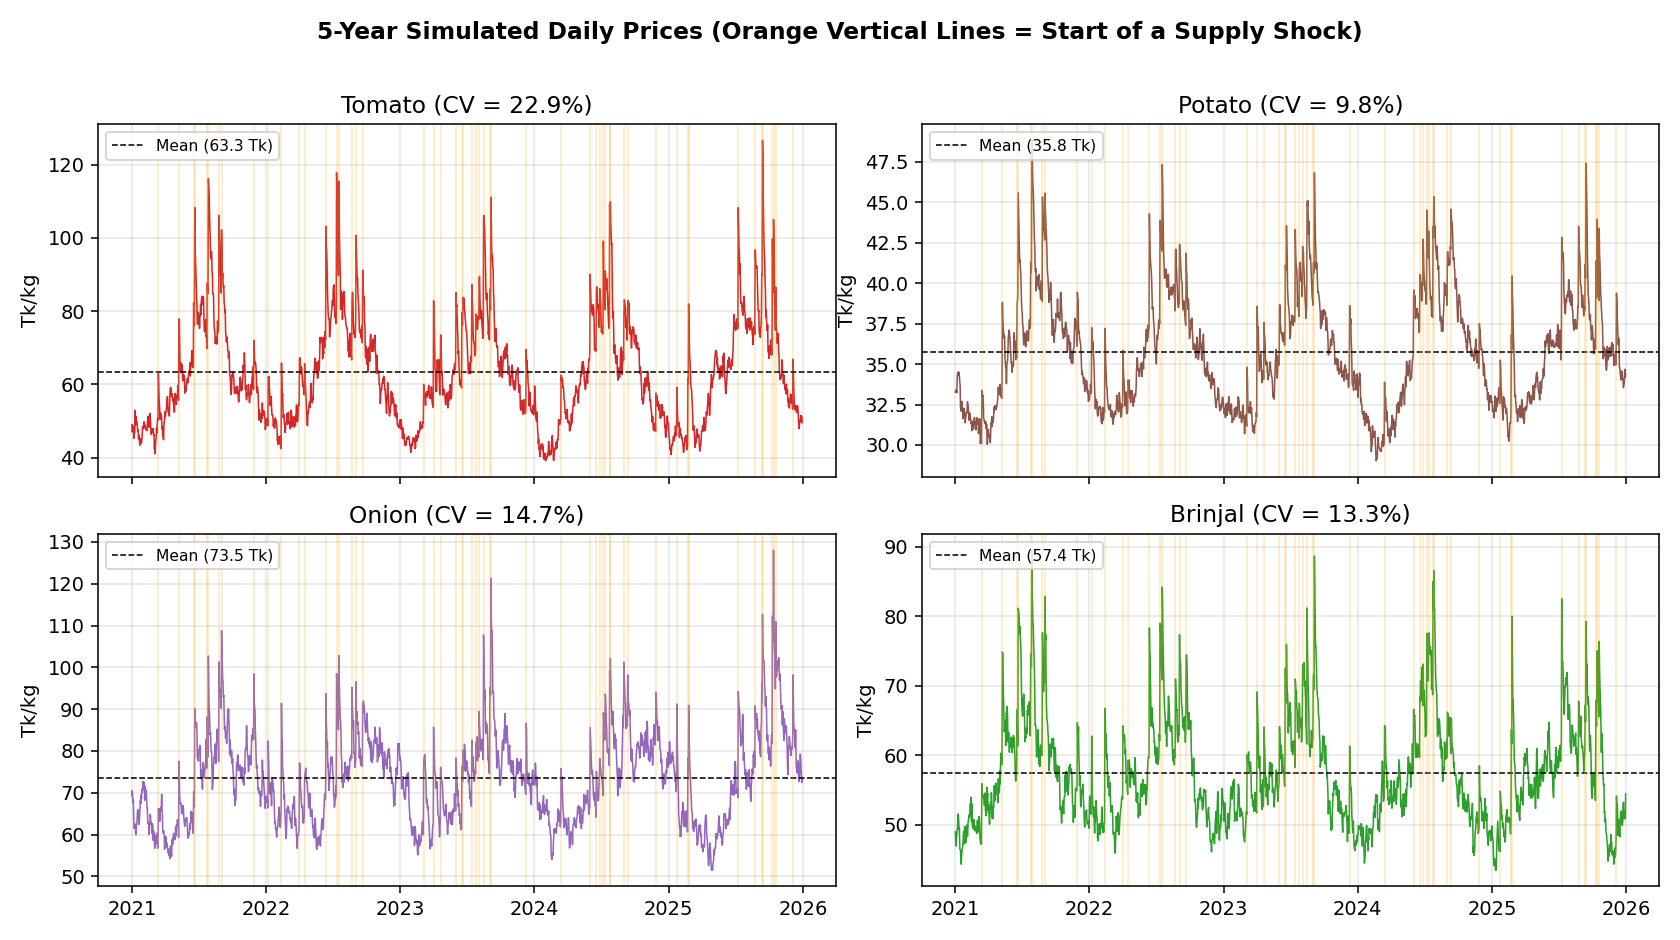

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
colors = ["tab:red", "tab:brown", "tab:purple", "tab:green"]
shock_days = df.index[df["ShockStart"]]

for ax, name, col in zip(axes.ravel(), veg_cols, colors):
    ax.plot(df.index, df[name], color=col, linewidth=0.8)
    ax.axhline(df[name].mean(), color="black", linestyle="--", linewidth=0.8, label=f"Mean ({df[name].mean():.1f} Tk)")
    for d in shock_days:
        ax.axvline(d, color="orange", alpha=0.25, linewidth=0.8)
    ax.set_title(f"{name} (CV = {summary.loc[name, 'CV (%)']:.1f}%)")
    ax.set_ylabel("Tk/kg"); ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("5-Year Simulated Daily Prices (Orange Vertical Lines = Start of a Supply Shock)", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

### 5.3 Price distributions & 5.4 Seasonal pattern (average Tk/kg by season)

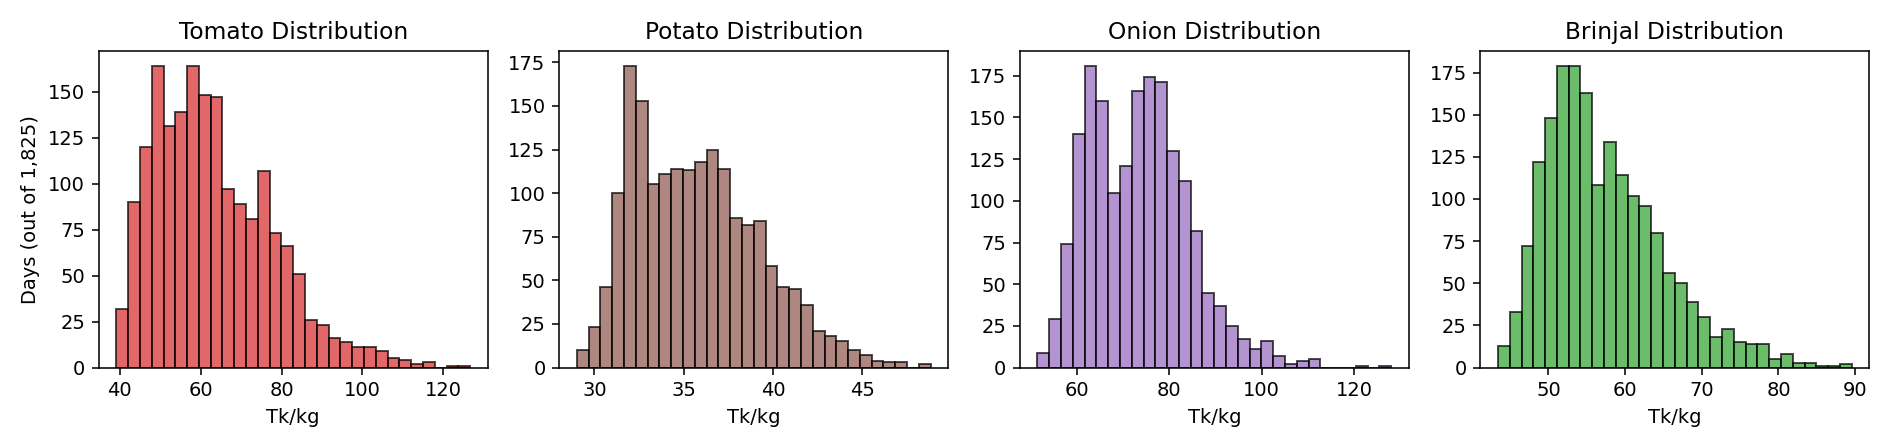

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.2))
for ax, name, col in zip(axes, veg_cols, colors):
    ax.hist(df[name], bins=30, color=col, alpha=0.7, edgecolor="black")
    ax.set_title(f"{name} Distribution"); ax.set_xlabel("Tk/kg")
axes[0].set_ylabel("Days (out of 1,825)")
plt.tight_layout(); plt.show()

         Tomato  Potato  Onion  Brinjal
Season                                 
Winter    49.53   33.01  70.09    50.97
Summer    56.78   33.13  63.32    55.72
Monsoon   78.63   39.41  79.58    64.99
Autumn    62.78   36.46  81.55    54.14

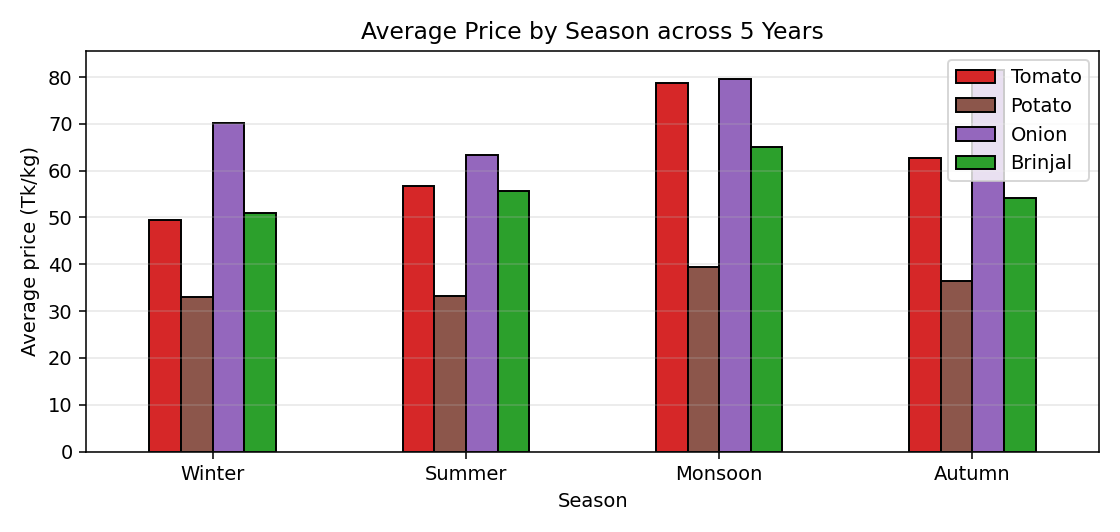

In [11]:
order = ["Winter", "Summer", "Monsoon", "Autumn"]
season_mean = df.groupby("Season")[veg_cols].mean().reindex(order)
display(season_mean.round(2))

ax = season_mean.plot(kind="bar", figsize=(8, 3.8), edgecolor="black", color=colors)
plt.ylabel("Average price (Tk/kg)"); plt.title("Average Price by Season across 5 Years")
plt.xticks(rotation=0); plt.grid(True, axis="y", alpha=0.3); plt.tight_layout(); plt.show()

## 6. Cross-Crop Co-Movement & Shared Factor Analysis (`SIM_Lab1` & `SIM_Lab2`)

In our model, each vegetable has its own independent daily noise $\varepsilon_{v,t}$, but all four vegetables experience the **same market-wide supply shock $Z_t$** (scaled by sensitivity $k_v$). We use the matrix and eigenvalue tools from **Lab 1** and **Lab 2** to answer a concrete modeling question: *How much of the day-to-day movement across the four vegetables comes from one shared market factor?*

- **Why correlate daily log-returns instead of price levels?** Correlating raw price levels ($P_{v,t}$) mixes together deterministic seasonal cycles and multi-day shock persistence. Taking **daily log-returns** $r_{v,t} = \ln(P_{v,t} / P_{v,t-1})$ removes the slow seasonal level and isolates same-day jumps.
- **Why compute eigenvalues of the correlation matrix $R$ instead of the covariance matrix?** In a raw covariance matrix, Tomato's eigenvalue looks huge simply because Tomato has a larger variance in $\text{Tk}^2$. Using the **$4\times 4$ log-return correlation matrix $R$** standardizes all four vegetables to unit variance (so the `4` eigenvalues sum to exactly `4.0`), showing the true share of variance explained by the common shock factor.

Highest Seasonal Average : 81.55 Tk/kg -> (Autumn, Onion)
Lowest Seasonal Average  : 33.01 Tk/kg -> (Winter, Potato)

--- Daily Log-Return Correlation Matrix (R) ---
         Tomato  Potato  Onion  Brinjal
Tomato     1.00    0.72   0.68     0.68
Potato     0.72    1.00   0.70     0.69
Onion      0.68    0.70   1.00     0.67
Brinjal    0.68    0.69   0.67     1.00
Matrix shape: (4, 4) | Rank: 4 | Determinant det(R): 0.0923
Eigenvalues of R (sum = 4.0): [3.064 0.335 0.323 0.279]
Share of variance explained by each factor: [76.6  8.4  8.1  7. ]%
-> Dominant 1st eigenvalue explains 76.6% of daily return variance across all 4 crops (the shared shock Z_t).

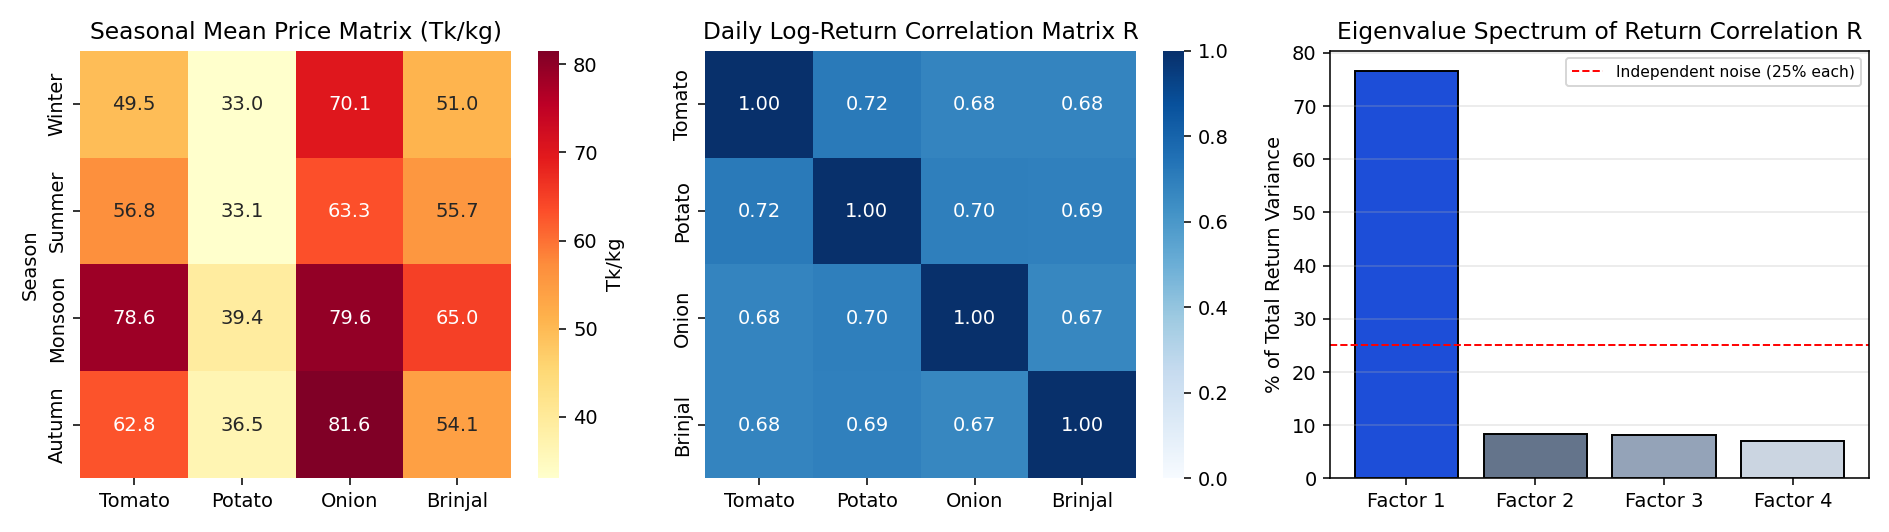

In [12]:
# 6.1 Lab 1 2D Index Unraveling on the 4x4 Seasonal Mean Matrix
season_mat = season_mean.values
max_r, max_c = np.unravel_index(np.argmax(season_mat), season_mat.shape)
min_r, min_c = np.unravel_index(np.argmin(season_mat), season_mat.shape)
print(f"Highest Seasonal Average : {season_mat[max_r, max_c]:.2f} Tk/kg -> ({order[max_r]}, {veg_cols[max_c]})")
print(f"Lowest Seasonal Average  : {season_mat[min_r, min_c]:.2f} Tk/kg -> ({order[min_r]}, {veg_cols[min_c]})")

# 6.2 Daily Log-Returns vs. Price Levels Correlation
log_returns = np.log(df[veg_cols] / df[veg_cols].shift(1)).dropna()
corr_levels = df[veg_cols].corr()
corr_returns = log_returns.corr()

# 6.3 Lab 2 Eigenvalue & Determinant Analysis on the 4x4 Log-Return Correlation Matrix R
eigvals, eigvecs = np.linalg.eigh(corr_returns.values)
eigvals = eigvals[::-1]  # sort descending
var_explained = eigvals / eigvals.sum() * 100
det_R = np.linalg.det(corr_returns.values)
rank_R = np.linalg.matrix_rank(corr_returns.values)

print("\n--- Daily Log-Return Correlation Matrix (R) ---")
display(corr_returns.round(3))
print(f"Matrix shape: {corr_returns.shape} | Rank: {rank_R} | Determinant det(R): {det_R:.4f}")
print(f"Eigenvalues of R (sum = {eigvals.sum():.1f}): {np.round(eigvals, 3)}")
print(f"Share of variance explained by each factor: {np.round(var_explained, 1)}%")
print(f"-> Dominant 1st eigenvalue explains {var_explained[0]:.1f}% of daily return variance across all 4 crops (the shared shock Z_t).")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
sns.heatmap(season_mean, annot=True, fmt=".1f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "Tk/kg"})
axes[0].set_title("Seasonal Mean Price Matrix (Tk/kg)")

sns.heatmap(corr_returns, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Daily Log-Return Correlation Matrix R")

axes[2].bar([f"Factor {i+1}" for i in range(4)], var_explained, color=["#1d4ed8", "#64748b", "#94a3b8", "#cbd5e1"], edgecolor="black")
axes[2].axhline(25.0, color="red", linestyle="--", linewidth=1, label="Independent noise (25% each)")
axes[2].set_ylabel("% of Total Return Variance"); axes[2].set_title("Eigenvalue Spectrum of Return Correlation R")
axes[2].legend(fontsize=8); axes[2].grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 7. One-Sample *t*-Test: Is a Claimed Average Price Correct? (`SIM_Day_6` & `T_Day_6`)

**Scenario.** A market committee claims that the average retail price of **tomato is `60 Tk/kg`**. We check this claim using a random sample of **`30` market days** drawn without replacement via `np.random.permutation`.

- **$H_0$:** $\mu = 60$ Tk/kg
- **$H_1$:** $\mu \neq 60$ Tk/kg ($\alpha = 0.05$, two-tailed, $df = n - 1 = 29$)
- **Test Statistic:** $t = \frac{\bar{x} - \mu_0}{s / \sqrt{n}}$

> **Methodological Caveat (Autocorrelation & Normality):** Because daily prices have AR(1) persistence ($\varphi = 0.90$) and monsoon shock spikes, consecutive days are not independent. Drawing 30 days at random across 5 years (`1,825` days) spreads the observations far apart in time, which reduces—but does not completely eliminate—serial dependence.

Sample size: 30
Sample mean: 67.93 Tk/kg  (True 5-year mean: 63.30 Tk/kg)
Sample std (ddof=1): 19.97 Tk/kg
t-statistic (scipy): 2.17  |  t-statistic (manual): 2.17
Degrees of freedom: 29
p-value: 0.0379
95% CI for the mean: [60.47, 75.39] Tk/kg
Shapiro-Wilk p-value = 0.0665 -> no strong evidence against normality (p > 0.05)
Repeated sampling check: rejected 60 Tk/kg in 19.9% of 2,000 random 30-day surveys.
Decision: Reject H0 (borderline: p = 0.0379 < 0.05, but power is only 19.9% at n=30).

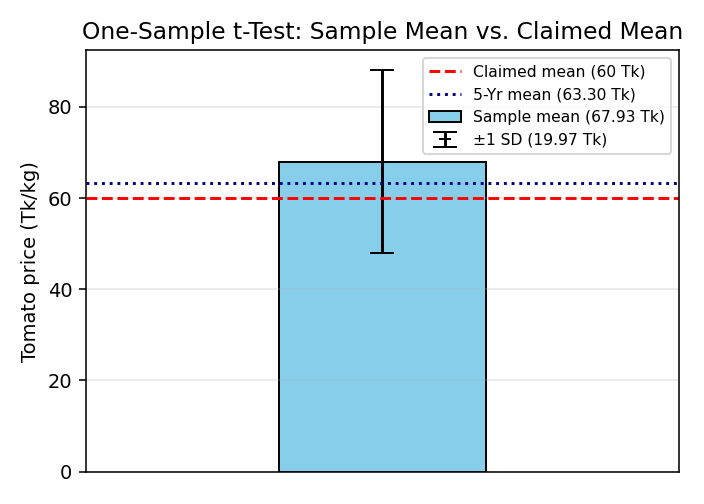

In [13]:
np.random.seed(7)
idx = np.random.permutation(len(df))[:30]          # random sample of 30 days
sample = df["Tomato"].values[idx]
claimed_mean = 60
alpha = 0.05

n = len(sample)
sample_mean = sample.mean()
sample_std = sample.std(ddof=1)
t_manual = (sample_mean - claimed_mean) / (sample_std / np.sqrt(n))
t_stat, p_value = stats.ttest_1samp(sample, claimed_mean)
ci_1samp = stats.t.interval(0.95, df=n - 1, loc=sample_mean, scale=stats.sem(sample))

# Assumption check: Shapiro-Wilk normality test (H0: sample comes from a Normal distribution)
w_stat, p_norm = stats.shapiro(sample)
norm_msg = "no strong evidence against normality (p > 0.05)" if p_norm > 0.05 else "sample departs significantly from normality (p <= 0.05)"

# Stability / Power check: repeat the 30-day survey 2,000 times
np.random.seed(123)
true_tomato_mean = df["Tomato"].mean()
rej_count = 0
for _ in range(2000):
    smp = df["Tomato"].values[np.random.permutation(len(df))[:30]]
    if stats.ttest_1samp(smp, claimed_mean)[1] < 0.05:
        rej_count += 1
power_1samp = rej_count / 2000 * 100

print(f"Sample size: {n}")
print(f"Sample mean: {sample_mean:.2f} Tk/kg  (True 5-year mean: {true_tomato_mean:.2f} Tk/kg)")
print(f"Sample std (ddof=1): {sample_std:.2f} Tk/kg")
print(f"t-statistic (scipy): {t_stat:.2f}  |  t-statistic (manual): {t_manual:.2f}")
print(f"Degrees of freedom: {n - 1}")
print(f"p-value: {p_value:.4f}")
print(f"95% CI for the mean: [{ci_1samp[0]:.2f}, {ci_1samp[1]:.2f}] Tk/kg")
print(f"Shapiro-Wilk p-value = {p_norm:.4f} -> {norm_msg}")
print(f"Repeated sampling check: rejected {claimed_mean} Tk/kg in {power_1samp:.1f}% of 2,000 random 30-day surveys.")

if p_value < alpha:
    print(f"Decision: Reject H0 (borderline: p = {p_value:.4f} < 0.05, but power is only {power_1samp:.1f}% at n=30).")
else:
    print(f"Decision: Fail to reject H0 (p = {p_value:.4f} >= 0.05; n=30 has only {power_1samp:.1f}% power to detect the true {true_tomato_mean:.2f} Tk/kg mean).")

plt.figure(figsize=(5, 3.6))
plt.bar(1, sample_mean, width=0.35, color="skyblue", edgecolor="black", label=f"Sample mean ({sample_mean:.2f} Tk)")
plt.errorbar(1, sample_mean, yerr=sample_std, fmt="k_", capsize=6, linewidth=1.5, label=f"±1 SD ({sample_std:.2f} Tk)")
plt.axhline(claimed_mean, color="r", linestyle="--", label=f"Claimed mean ({claimed_mean} Tk)")
plt.axhline(true_tomato_mean, color="navy", linestyle=":", label=f"5-Yr mean ({true_tomato_mean:.2f} Tk)")
plt.xlim(0.5, 1.5); plt.xticks([])
plt.ylabel("Tomato price (Tk/kg)"); plt.title("One-Sample t-Test: Sample Mean vs. Claimed Mean")
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

**Interpretation (`seed=42` simulation, `seed=7` sample).** For this specific 30-day sample, $p = 0.0379 < 0.05$ and the 95% CI (`[60.47, 75.39]`) barely excludes `60`, giving a **borderline rejection of $H_0$** while passing the Shapiro-Wilk normality check ($p = 0.0665 > 0.05$). However, the 2,000-survey power check is essential context: because the true 5-year mean (`63.30 Tk/kg`) is only `3.30 Tk/kg` above `60` while the standard deviation is large (`14.52 Tk/kg` overall, `19.97 Tk/kg` in the sample), **only `19.9%` (roughly 1 in 5) of random 30-day samples reject the claim**. A 30-day sample is too small in such a volatile market to reliably detect a ~3 Tk difference.

## 8. Two-Sample *t*-Test: Winter vs. Monsoon Tomato Prices (`Two_Sample_t_Test.pptx.pdf`)

**Question.** Are retail tomato prices significantly different between **Winter** and **Monsoon**? We draw `30` random Winter days and `30` random Monsoon days (`seed=11`) and compare:
1. **Levene's Test (`stats.levene`)** — tests equality of variances ($H_0: \sigma_{\text{Winter}}^2 = \sigma_{\text{Monsoon}}^2$).
2. **Pooled-Variance *t*-Test (`equal_var=True`)** — assumes equal population variances:
   $$t = \frac{\bar{X}_1 - \bar{X}_2}{\sqrt{s_p^2\left(\frac{1}{n_1}+\frac{1}{n_2}\right)}}, \qquad s_p^2 = \frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}$$
3. **Welch's *t*-Test (`equal_var=False`)** — allows unequal variances and adjusts degrees of freedom via the Welch–Satterthwaite formula.

Winter  (n=30): mean = 48.59 Tk/kg, variance = 24.65, std = 4.96
Monsoon (n=30): mean = 80.56, variance = 188.76, std = 13.74
Mean difference (Winter - Monsoon): -31.97 Tk/kg
Levene's test p-value = 0.0025 -> Variances differ significantly -> Welch's t-test is the safer choice

[Pooled t-test] s_p^2 = 106.71 | t (scipy) = -11.99, t (manual) = -11.99, df = 58, p = 2.47e-17, 95% CI = [-37.31, -26.63]
[Welch  t-test] t (scipy) = -11.99, t (manual) = -11.99, Welch df = 36.45, p = 3.30e-14, 95% CI = [-37.38, -26.56]

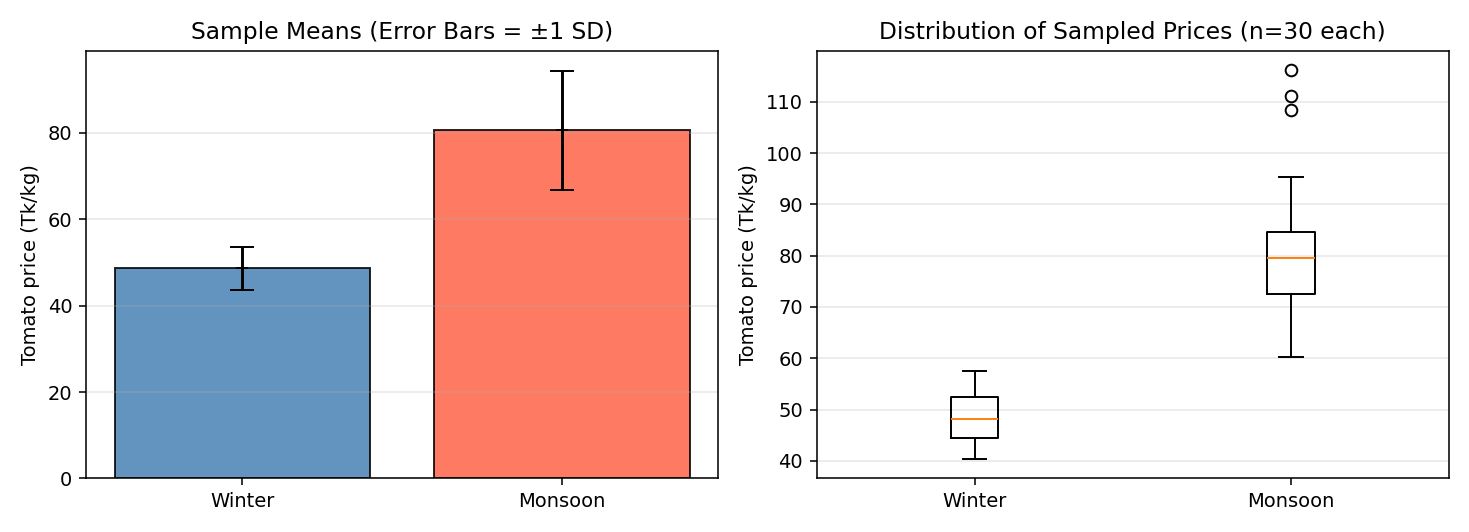

In [14]:
np.random.seed(11)
winter  = df.loc[df["Season"] == "Winter",  "Tomato"].values
monsoon = df.loc[df["Season"] == "Monsoon", "Tomato"].values

data1 = winter[np.random.permutation(len(winter))[:30]]
data2 = monsoon[np.random.permutation(len(monsoon))[:30]]

n1, n2 = len(data1), len(data2)
s1_sq, s2_sq = data1.var(ddof=1), data2.var(ddof=1)
mean_diff = data1.mean() - data2.mean()

# Levene's test for equal variance
lev_stat, lev_p = stats.levene(data1, data2)

# 1) Pooled t-test (equal_var=True + manual formula)
t_pool, p_pool = stats.ttest_ind(data1, data2, equal_var=True)
sp_sq = ((n1 - 1) * s1_sq + (n2 - 1) * s2_sq) / (n1 + n2 - 2)
se_pool = np.sqrt(sp_sq * (1/n1 + 1/n2))
df_pool = n1 + n2 - 2
ci_pool = stats.t.interval(0.95, df_pool, loc=mean_diff, scale=se_pool)

# 2) Welch's t-test (equal_var=False + manual formula)
t_welch, p_welch = stats.ttest_ind(data1, data2, equal_var=False)
se_welch = np.sqrt(s1_sq / n1 + s2_sq / n2)
df_welch = (s1_sq/n1 + s2_sq/n2) ** 2 / ((s1_sq/n1) ** 2 / (n1 - 1) + (s2_sq/n2) ** 2 / (n2 - 1))
ci_welch = stats.t.interval(0.95, df_welch, loc=mean_diff, scale=se_welch)

print(f"Winter  (n={n1}): mean = {data1.mean():.2f} Tk/kg, variance = {s1_sq:.2f}, std = {data1.std(ddof=1):.2f}")
print(f"Monsoon (n={n2}): mean = {data2.mean():.2f}, variance = {s2_sq:.2f}, std = {data2.std(ddof=1):.2f}")
print(f"Mean difference (Winter - Monsoon): {mean_diff:.2f} Tk/kg")
print(f"Levene's test p-value = {lev_p:.4f} ->",
      "Variances look equal (pooled t-test acceptable)" if lev_p > 0.05 else "Variances differ significantly -> Welch's t-test is the safer choice")
print(f"\n[Pooled t-test] s_p^2 = {sp_sq:.2f} | t (scipy) = {t_pool:.2f}, t (manual) = {mean_diff/se_pool:.2f}, df = {df_pool}, p = {p_pool:.2e}, 95% CI = [{ci_pool[0]:.2f}, {ci_pool[1]:.2f}]")
print(f"[Welch  t-test] t (scipy) = {t_welch:.2f}, t (manual) = {mean_diff/se_welch:.2f}, Welch df = {df_welch:.2f}, p = {p_welch:.2e}, 95% CI = [{ci_welch[0]:.2f}, {ci_welch[1]:.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].bar(["Winter", "Monsoon"], [data1.mean(), data2.mean()], color=["steelblue", "tomato"], alpha=0.85, edgecolor="black")
axes[0].errorbar(["Winter", "Monsoon"], [data1.mean(), data2.mean()],
                 yerr=[data1.std(ddof=1), data2.std(ddof=1)], fmt="k_", capsize=6, linewidth=1.5)
axes[0].set_ylabel("Tomato price (Tk/kg)"); axes[0].set_title("Sample Means (Error Bars = ±1 SD)")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].boxplot([data1, data2], tick_labels=["Winter", "Monsoon"])
axes[1].set_ylabel("Tomato price (Tk/kg)"); axes[1].set_title("Distribution of Sampled Prices (n=30 each)")
axes[1].grid(True, axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Chi-Square Goodness-of-Fit: Are Price Shocks Spread Evenly Through the Year? (`Chi Square.pptx` & `CP_5`)

**Question.** If supply shocks occurred with equal probability on every day of the year, each season's expected shock count would be proportional to the number of calendar days in that season:

$$E_i = N_{\text{shocks}} \times \frac{\text{days in season } i}{\text{total days}}, \qquad \chi^2 = \sum_{i=1}^{4} \frac{(O_i - E_i)^2}{E_i}$$

- **$H_0$:** Shocks occur at an equal daily rate across all four seasons.
- **$H_1$:** Shock rates differ across seasons ($\alpha = 0.05$, $df = 4 - 1 = 3$).

         Days  Observed shocks (O)  Expected shocks (E)  (O - E)^2 / E
Winter    450                    7                13.32           3.00
Summer    460                    8                13.61           2.31
Monsoon   610                   34                18.05          14.10
Autumn    305                    5                 9.02           1.79

Chi-square statistic (manual): 21.20 | scipy: 21.20
Degrees of freedom: 3 | Critical value (0.05): 7.81 | p-value: 0.000096
All expected counts >= 5 (test is valid): True
Reject H0: shocks concentrate significantly in Monsoon.

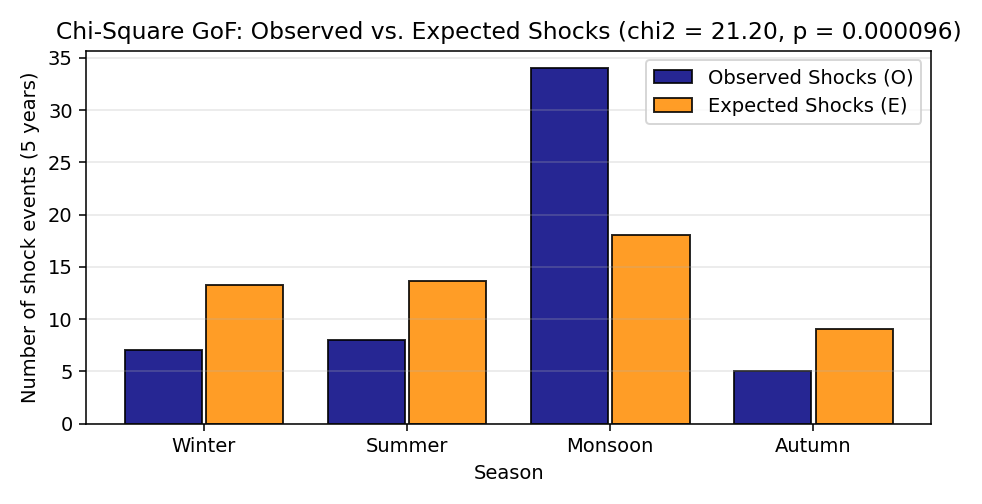

In [15]:
order = ["Winter", "Summer", "Monsoon", "Autumn"]

observed_chi = df.groupby("Season")["ShockStart"].sum().reindex(order).values
days_in_season = df["Season"].value_counts().reindex(order).values
expected_chi = observed_chi.sum() * days_in_season / days_in_season.sum()

chi_sq = np.sum((observed_chi - expected_chi) ** 2 / expected_chi)
dof = len(observed_chi) - 1
critical_chi = stats.chi2.ppf(0.95, dof)
p_chi = stats.chi2.sf(chi_sq, dof)

chi_table = pd.DataFrame({
    "Days": days_in_season,
    "Observed shocks (O)": observed_chi,
    "Expected shocks (E)": expected_chi.round(2),
    "(O - E)^2 / E": ((observed_chi - expected_chi) ** 2 / expected_chi).round(2)
}, index=order)
display(chi_table)

print(f"\nChi-square statistic (manual): {chi_sq:.2f} | scipy: {stats.chisquare(observed_chi, expected_chi).statistic:.2f}")
print(f"Degrees of freedom: {dof} | Critical value (0.05): {critical_chi:.2f} | p-value: {p_chi:.6f}")
print("All expected counts >= 5 (test is valid):", bool(np.all(expected_chi >= 5)))
print("Reject H0: shocks concentrate significantly in Monsoon." if chi_sq > critical_chi else "Fail to reject H0.")

x = np.arange(len(order))
plt.figure(figsize=(6.8, 3.6))
plt.bar(x - 0.2, observed_chi, width=0.38, label="Observed Shocks (O)", color="navy", alpha=0.85, edgecolor="black")
plt.bar(x + 0.2, expected_chi, width=0.38, label="Expected Shocks (E)", color="darkorange", alpha=0.85, edgecolor="black")
plt.xticks(x, order); plt.xlabel("Season"); plt.ylabel("Number of shock events (5 years)")
plt.title(f"Chi-Square GoF: Observed vs. Expected Shocks (chi2 = {chi_sq:.2f}, p = {p_chi:.6f})")
plt.legend(); plt.grid(True, axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 9.1 How reliable is this Chi-Square test? (2,000-History Power Simulation)
One 5-year history is a single random outcome. Below we simulate **`2,000` independent 5-year histories** (`seed=99`), verify how many satisfy the validity rule ($\forall E_i \ge 5$), and calculate the empirical **statistical power** (the percentage of valid 5-year histories where the test rejects $H_0$ at $\alpha = 0.05$).

In [16]:
np.random.seed(99)
n_hist = 2000
mon_mask = np.isin(dates.month, [6, 7, 8, 9])
p_day = np.where(mon_mask, P_MONSOON, P_OTHER)
events_mc = np.random.rand(n_hist, len(dates)) < p_day          # shock-start flags for 2,000 5-year histories

season_arr = seasons_of(dates)
rejections, usable = 0, 0
for i in range(n_hist):
    obs = np.array([events_mc[i, season_arr == s].sum() for s in order])
    if obs.sum() == 0:
        continue
    exp = obs.sum() * days_in_season / days_in_season.sum()
    if np.all(exp >= 5):
        usable += 1
        if np.sum((obs - exp) ** 2 / exp) > critical_chi:
            rejections += 1

power_chi = rejections / usable * 100
print(f"Histories where the Chi-Square test was valid (all E_i >= 5): {usable} of {n_hist}")
print(f"Chi-square rejected H0 in {rejections} of {usable} histories (Empirical Power = {power_chi:.1f}%)")

Histories where the Chi-Square test was valid (all E_i >= 5): 2000 of 2000
Chi-square rejected H0 in 1923 of 2000 histories (Empirical Power = 96.2%)

## 10. Monte Carlo Experiment: Household Budget Risk & 3D Seasonal Trajectory (`Monte_Carlo_Simulation_Basics.pptx.pdf` & `SIM_Day_8`)

### 10.1 Monthly Basket Distribution & True 95% Range (`[2.5, 97.5]` Percentiles)
A household buys a weekly basket of **`1 kg tomato + 2 kg potato + 1 kg onion + 1 kg brinjal`**, shopping `4` times per month (`days [0, 7, 14, 21]` in January vs. `days [181, 188, 195, 202]` in July). We simulate **`2,000` independent years** (`seed=2024`) and compute:
1. The true **95% range (`2.5th` to `97.5th` percentiles)** and **90% range (`5th` to `95th` percentiles)** of monthly spending.
2. A **Budget Sweep from `1,000 Tk` to `1,500 Tk`** showing how the exceedance probability $P(\text{Cost} > B)$ and coverage probability $P(\text{Cost} \le B)$ change across budget thresholds, alongside the exact **80th, 90th, 95th, and 97.5th percentile July budgets**.

In [17]:
np.random.seed(2024)
n_runs = 2000
year_dates = pd.date_range("2023-01-01", periods=365)
mc_prices, mc_events, _ = simulate(n_runs, year_dates)

basket = (1 * mc_prices["Tomato"] + 2 * mc_prices["Potato"]
          + 1 * mc_prices["Onion"] + 1 * mc_prices["Brinjal"])    # shape: 2000 runs x 365 days

jan_days  = [0, 7, 14, 21]          # four weekly shopping days in January
jul_days  = [181, 188, 195, 202]    # four weekly shopping days in July
jan_cost = basket[:, jan_days].sum(axis=1)
jul_cost = basket[:, jul_days].sum(axis=1)

budget = 1000
for label, cost in [("January (winter)", jan_cost), ("July (monsoon)  ", jul_cost)]:
    lo95, hi95 = np.percentile(cost, [2.5, 97.5])
    lo90, hi90 = np.percentile(cost, [5.0, 95.0])
    print(f"{label}: mean = {cost.mean():.0f} Tk, std = {cost.std():.0f} Tk | "
          f"95% range [2.5, 97.5] = [{lo95:.0f}, {hi95:.0f}] Tk | "
          f"90% range [5, 95] = [{lo90:.0f}, {hi90:.0f}] Tk | P(cost > {budget}) = {np.mean(cost > budget) * 100:.1f}%")

# Budget sweep across 1,000 to 1,500 Tk
budgets = [1000, 1100, 1200, 1250, 1300, 1350, 1400, 1450, 1500]
sweep_df = pd.DataFrame({
    "Budget Threshold (Tk)": budgets,
    "Jan Overrun P(Cost > B) (%)": [np.mean(jan_cost > b) * 100 for b in budgets],
    "Jul Overrun P(Cost > B) (%)": [np.mean(jul_cost > b) * 100 for b in budgets],
    "Jul Coverage P(Cost <= B) (%)": [np.mean(jul_cost <= b) * 100 for b in budgets],
})
print("\n--- Household Monthly Budget Sweep (1,000 Tk to 1,500 Tk) ---")
display(sweep_df.round(1))

cov_1250 = np.mean(jul_cost <= 1250) * 100
cov_1300 = np.mean(jul_cost <= 1300) * 100
jul_p80, jul_p90, jul_p95, jul_p975 = np.percentile(jul_cost, [80, 90, 95, 97.5])
print(f"\nJuly Budget Quantiles -> 80th pct: {jul_p80:.0f} Tk | 90th pct: {jul_p90:.0f} Tk | 95th pct: {jul_p95:.0f} Tk | 97.5th pct: {jul_p975:.0f} Tk")
print(f"July Coverage at 1,250–1,300 Tk -> {cov_1250:.1f}% to {cov_1300:.1f}% (approx {cov_1250:.0f}%–{cov_1300:.0f}%)")

shocks_per_year = mc_events.sum(axis=1)
peak_tomato = mc_prices["Tomato"].max(axis=1)
print(f"Expected shock events per year: {shocks_per_year.mean():.1f} (std {shocks_per_year.std():.1f})")
print(f"Average yearly peak tomato price: {peak_tomato.mean():.0f} Tk/kg | 95th percentile peak: {np.percentile(peak_tomato, 95):.0f} Tk/kg")

January (winter): mean = 937 Tk, std = 35 Tk | 95% range [2.5, 97.5] = [893, 1027] Tk | 90% range [5, 95] = [899, 1008] Tk | P(cost > 1000) = 6.8%
July (monsoon)  : mean = 1229 Tk, std = 84 Tk | 95% range [2.5, 97.5] = [1105, 1429] Tk | 90% range [5, 95] = [1118, 1383] Tk | P(cost > 1000) = 100.0%

--- Household Monthly Budget Sweep (1,000 Tk to 1,500 Tk) ---
   Budget Threshold (Tk)  Jan Overrun P(Cost > B) (%)  Jul Overrun P(Cost > B) (%)  Jul Coverage P(Cost <= B) (%)
0                   1000                          6.8                        100.0                            0.0
1                   1100                          0.2                         98.6                            1.5
2                   1200                          0.0                         58.1                           41.9
3                   1250                          0.0                         36.2                           63.8
4                   1300                          0.0               

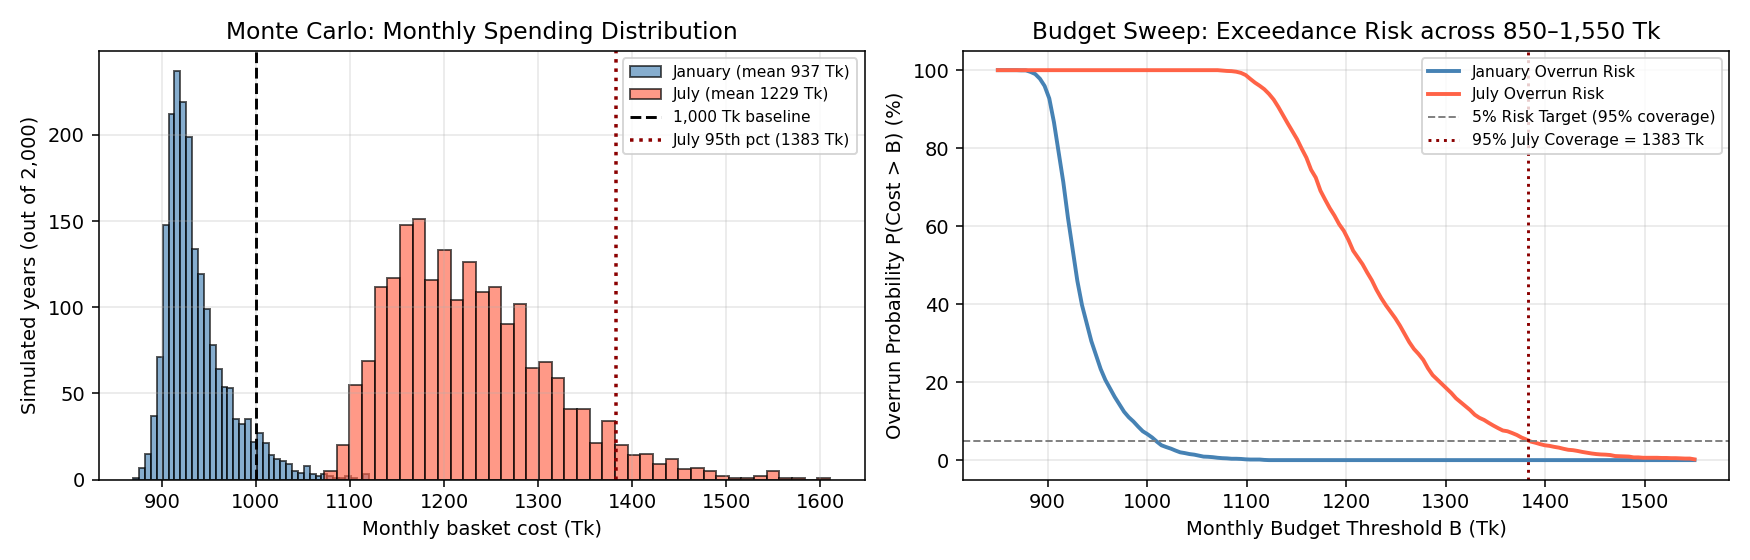

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
axes[0].hist(jan_cost, bins=40, alpha=0.65, color="steelblue", edgecolor="black", label=f"January (mean {jan_cost.mean():.0f} Tk)")
axes[0].hist(jul_cost, bins=40, alpha=0.65, color="tomato", edgecolor="black", label=f"July (mean {jul_cost.mean():.0f} Tk)")
axes[0].axvline(1000, color="black", linestyle="--", label="1,000 Tk baseline")
axes[0].axvline(jul_p95, color="darkred", linestyle=":", linewidth=1.8, label=f"July 95th pct ({jul_p95:.0f} Tk)")
axes[0].set_xlabel("Monthly basket cost (Tk)"); axes[0].set_ylabel("Simulated years (out of 2,000)")
axes[0].set_title("Monte Carlo: Monthly Spending Distribution")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

b_grid = np.linspace(850, 1550, 150)
axes[1].plot(b_grid, [np.mean(jan_cost > b) * 100 for b in b_grid], color="steelblue", linewidth=2, label="January Overrun Risk")
axes[1].plot(b_grid, [np.mean(jul_cost > b) * 100 for b in b_grid], color="tomato", linewidth=2, label="July Overrun Risk")
axes[1].axhline(5.0, color="gray", linestyle="--", linewidth=1, label="5% Risk Target (95% coverage)")
axes[1].axvline(jul_p95, color="darkred", linestyle=":", linewidth=1.5, label=f"95% July Coverage = {jul_p95:.0f} Tk")
axes[1].set_xlabel("Monthly Budget Threshold B (Tk)"); axes[1].set_ylabel("Overrun Probability P(Cost > B) (%)")
axes[1].set_title("Budget Sweep: Exceedance Risk across 850–1,550 Tk")
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 10.2 3D Seasonal Phase-Space Trajectory & Interactive `FuncAnimation` Template (`SIM_Day_8` & `CP_06`)
Following **Lab Day 8 (`SIM_Day_8.ipynb`)**, we map the 365-day calendar onto a unit circle $(X_t = \cos(2\pi d_t / 365),\; Y_t = \sin(2\pi d_t / 365))$ and plot Year-1 daily Tomato price $Z_t = P_{\text{Tomato},t}$ on the vertical axis. We also provide a ready-to-run `FuncAnimation` template (uncomment `HTML(anim_obj.to_jshtml())` in Jupyter/Colab to view the interactive player inline).

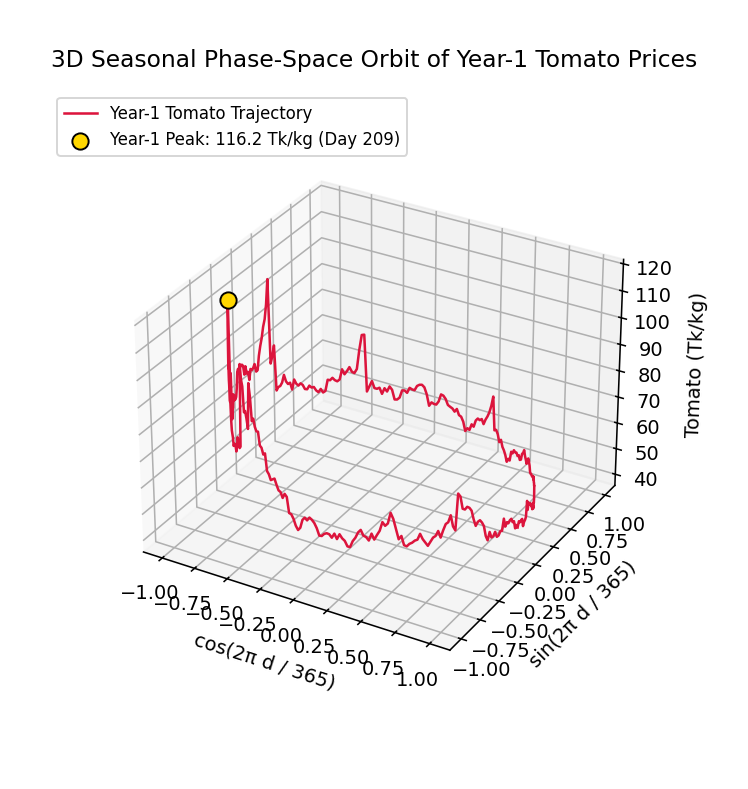

In [19]:
# Extract Year 1 (365 days) for 3D seasonal phase-space visualization
df_y1 = df.iloc[:365].copy()
theta_y1 = 2 * np.pi * df_y1.index.dayofyear.values / 365.0
x_phase = np.cos(theta_y1)
y_phase = np.sin(theta_y1)
z_tomato = df_y1["Tomato"].values
peak_idx_y1 = int(np.argmax(z_tomato))

fig = plt.figure(figsize=(8.2, 5.4))
ax3d = fig.add_subplot(111, projection="3d")
ax3d.set_box_aspect(None, zoom=0.84)  # zoom out slightly so the z-axis label has full margin
ax3d.plot(x_phase, y_phase, z_tomato, color="crimson", linewidth=1.3, label="Year-1 Tomato Trajectory")
ax3d.scatter(x_phase[peak_idx_y1], y_phase[peak_idx_y1], z_tomato[peak_idx_y1],
             color="gold", edgecolor="black", s=70, zorder=5,
             label=f"Year-1 Peak: {z_tomato[peak_idx_y1]:.1f} Tk/kg (Day {df_y1.index.dayofyear[peak_idx_y1]})")
ax3d.set_xlabel("cos(2π d / 365)", labelpad=6)
ax3d.set_ylabel("sin(2π d / 365)", labelpad=6)
ax3d.set_zlabel("Tomato (Tk/kg)", labelpad=8)
ax3d.set_title("3D Seasonal Phase-Space Orbit of Year-1 Tomato Prices", pad=12)
ax3d.legend(loc="upper left", fontsize=8.5)
fig.subplots_adjust(left=0.05, right=0.88, bottom=0.06, top=0.92)
plt.show()

# Reusable FuncAnimation template (Lab Day 8 / CP 06):
# In interactive Jupyter/Colab, uncomment the last two lines to render the HTML5 video player inline.
def build_phase_space_animation(x_arr, y_arr, z_arr, step=5, interval_ms=40):
    """Lab Day 8 / CP 06 FuncAnimation template for the 3D seasonal price trajectory."""
    fig_anim = plt.figure(figsize=(6.5, 4.8))
    ax_anim = fig_anim.add_subplot(111, projection="3d")
    ax_anim.set_box_aspect(None, zoom=0.84)
    ax_anim.set_xlim(-1.1, 1.1); ax_anim.set_ylim(-1.1, 1.1)
    ax_anim.set_zlim(z_arr.min() * 0.9, z_arr.max() * 1.05)
    ax_anim.set_xlabel("cos(2π d / 365)"); ax_anim.set_ylabel("sin(2π d / 365)"); ax_anim.set_zlabel("Tk/kg")
    line, = ax_anim.plot([], [], [], color="crimson", lw=1.5)
    point, = ax_anim.plot([], [], [], "o", color="gold", markeredgecolor="black", markersize=7)
    frames = list(range(0, len(z_arr), step))

    def update(frame):
        line.set_data(x_arr[:frame+1], y_arr[:frame+1])
        line.set_3d_properties(z_arr[:frame+1])
        point.set_data([x_arr[frame]], [y_arr[frame]])
        point.set_3d_properties([z_arr[frame]])
        return line, point

    anim = FuncAnimation(fig_anim, update, frames=frames, interval=interval_ms, blit=False)
    plt.close(fig_anim)
    return anim

anim_template = build_phase_space_animation(x_phase, y_phase, z_tomato)
# from IPython.display import HTML
# HTML(anim_template.to_jshtml())

## 11. Dynamic Results Summary, Limitations & Real-Data Extension

To guarantee that our summary table and key quantitative conclusions can **never go stale** if a user changes a random seed or model parameter and re-runs the notebook, the code cell below builds both the final results table and the quantitative conclusion lines dynamically using f-strings from the live variables computed above.

In [20]:
summary_table = pd.DataFrame([
    {
        "Analysis / Module": "Lab 3: Uniformity Check",
        "Method": "10-bin Chi-Square GoF (n=10,000)",
        "Live Quantitative Result": f"chi2 = {chi_sq_u:.2f} < {critical_u:.2f} (p = {p_val_u:.4f})",
        "Decision & Caveat": "Fail to reject H0 (generator is uniform)" if chi_sq_u <= critical_u else "Reject H0"
    },
    {
        "Analysis / Module": "Lab 1 & 2: Return Co-Movement",
        "Method": "Log-return correlation R & eigenvalues",
        "Live Quantitative Result": f"det(R) = {det_R:.4f}, Rank = {rank_R}, Top eigenvalue = {eigvals[0]:.2f} ({var_explained[0]:.1f}% var)",
        "Decision & Caveat": "1 dominant shared shock factor drives cross-crop daily jumps"
    },
    {
        "Analysis / Module": "Lab 6: Claimed Tomato Mean = 60 Tk",
        "Method": "One-sample t-test (n=30) + 2,000 repeats",
        "Live Quantitative Result": f"mean = {sample_mean:.2f} Tk, t = {t_stat:.2f}, p = {p_value:.4f}, Shapiro p = {p_norm:.4f}",
        "Decision & Caveat": f"{'Reject H0 (borderline)' if p_value < 0.05 else 'Fail to reject H0'}; low power ({power_1samp:.1f}% at n=30; true mean = {true_tomato_mean:.2f} Tk)"
    },
    {
        "Analysis / Module": "Lecture: Winter vs. Monsoon Tomato",
        "Method": "Levene + Pooled & Welch Two-Sample t-test",
        "Live Quantitative Result": f"Winter {data1.mean():.2f} vs Monsoon {data2.mean():.2f} Tk; Levene p = {lev_p:.4f}; Welch t = {t_welch:.2f} (df = {df_welch:.2f}, p = {p_welch:.2e})",
        "Decision & Caveat": f"Reject H0 (Monsoon is {-mean_diff:.2f} Tk/kg higher; 95% Welch CI for Winter - Monsoon: [{ci_welch[0]:.2f}, {ci_welch[1]:.2f}])"
    },
    {
        "Analysis / Module": "Lecture / CP 5: Shock Timing",
        "Method": "Unequal-season Chi-Square GoF + Power",
        "Live Quantitative Result": f"O = {observed_chi.tolist()}, E = {np.round(expected_chi, 2).tolist()}; chi2 = {chi_sq:.2f} (p = {p_chi:.6f})",
        "Decision & Caveat": f"Reject H0 (Shocks concentrate in Monsoon; 5-yr test power = {power_chi:.1f}%)"
    },
    {
        "Analysis / Module": "Monte Carlo: Household Basket",
        "Method": "2,000 simulated years + Budget sweep",
        "Live Quantitative Result": f"Jan mean {jan_cost.mean():.0f} Tk (95% [{np.percentile(jan_cost,2.5):.0f}, {np.percentile(jan_cost,97.5):.0f}]) vs Jul {jul_cost.mean():.0f} Tk (95% [{np.percentile(jul_cost,2.5):.0f}, {np.percentile(jul_cost,97.5):.0f}])",
        "Decision & Caveat": f"1,250–1,300 Tk covers {cov_1250:.1f}%–{cov_1300:.1f}% (~{cov_1250:.0f}%–{cov_1300:.0f}%) of Julys; 95% July coverage requires {jul_p95:.0f} Tk (97.5% = {jul_p975:.0f} Tk)"
    }
])
display(summary_table)

print("\n--- Dynamic Key Takeaways (computed from current run) ---")
print(f"1. Perishability vs. Storability: Tomato CV = {summary.loc['Tomato', 'CV (%)']:.2f}% vs. Potato CV = {summary.loc['Potato', 'CV (%)']:.2f}%.")
print(f"2. Power Contrast: 5-year Chi-Square shock timing power = {power_chi:.1f}%, whereas n=30 One-Sample t-test power = {power_1samp:.1f}% (true mean {true_tomato_mean:.2f} vs. {claimed_mean} Tk, gap = {true_tomato_mean - claimed_mean:.2f} Tk/kg).")
print(f"3. July Budget Coverage: 1,250–1,300 Tk covers {cov_1250:.1f}%–{cov_1300:.1f}% (~{cov_1250:.0f}%–{cov_1300:.0f}%) of Julys; 95% coverage requires {jul_p95:.0f} Tk/month (97.5% requires {jul_p975:.0f} Tk/month).")

                    Analysis / Module                                     Method                                                                          Live Quantitative Result                                                                                            Decision & Caveat
0             Lab 3: Uniformity Check           10-bin Chi-Square GoF (n=10,000)                                                                  chi2 = 9.75 < 16.92 (p = 0.3711)                                                                     Fail to reject H0 (generator is uniform)
1       Lab 1 & 2: Return Co-Movement     Log-return correlation R & eigenvalues                                      det(R) = 0.0923, Rank = 4, Top eigenvalue = 3.06 (76.6% var)                                                 1 dominant shared shock factor drives cross-crop daily jumps
2  Lab 6: Claimed Tomato Mean = 60 Tk   One-sample t-test (n=30) + 2,000 repeats                                         mean = 67.93 Tk

### 11.1 Conclusions (Baseline `seed=42` Run)
1. **Multiplicative dynamics with persistence:** Combining a seasonal wave, persistent daily noise ($\varphi = 0.90$), and decaying monsoon supply shocks ($\text{DECAY} = 0.85$) reproduces realistic retail price behavior without ever generating negative prices.
2. **Perishability vs. storability (`seed=42`):** Perishable **Tomato** (`CV = 22.94%`) fluctuates more than twice as much relative to its mean as cold-stored **Potato** (`CV = 9.79%`).
3. **Sample size & statistical power matter (`seed=42`):** While the two-sample Welch *t*-test (`Winter` vs. `Monsoon`) and the 5-year Chi-Square shock-timing test (`96.2%` power) detect strong seasonal differences reliably, a single 30-day one-sample *t*-test against `60 Tk/kg` has only `19.9%` power because daily volatility is large relative to the `3.30 Tk/kg` gap (`63.30` vs. `60.00`).
4. **Actionable budget quantiles (`seed=2024`):** Rather than relying on a single arbitrary `1,000 Tk` threshold, sweeping the budget from `1,000` to `1,500 Tk` shows that `1,250–1,300 Tk` covers `63.8%–81.5%` (about `64%–82%`) of July monsoon months, whereas covering **95% of July outcomes requires `1,383 Tk/month`** (and `1,429 Tk/month` for the 97.5th percentile).

### 11.2 Model Limitations
- **Synthetic data:** All baseline prices, amplitudes, and shock probabilities are modeling assumptions rather than econometric estimates from historical DAM/TCB market records.
- **Single market-wide shock process:** The model drives all four crops with one shared shock series $Z_t$; in reality, regional floods or import tariffs can hit specific crops (such as Onion) independently.
- **Autocorrelation vs. *t*-test independence:** Daily prices are serially correlated ($\varphi = 0.90$, $\text{DECAY} = 0.85$). Even when a 30-day random sample passes the Shapiro-Wilk normality check (as in our `seed=7` sample where $p = 0.0665 > 0.05$), the *t*-test's independence assumption is still only approximately satisfied because observations come from an autocorrelated time series (random sampling across 1,825 days reduces—but does not completely remove—this dependence).
- **No endogenous demand or policy feedback:** Consumer substitution, cold-storage release rules, imports, and government price ceilings are not explicitly modeled.

### 11.3 Using Real Market Data (Optional Extension)
If you collect daily retail prices (for example from the Department of Agricultural Marketing or TCB daily reports), save them as `real_prices.csv` with columns `Date, Tomato, Potato, Onion, Brinjal` and run the template below:

In [21]:
# --- OPTIONAL: replace simulated data with real CSV market records ---
# real = pd.read_csv("real_prices.csv", parse_dates=["Date"]).set_index("Date")
# real["Season"] = seasons_of(real.index)
# real["ShockStart"] = (real["Tomato"].pct_change() > 0.15).astype(int)  # e.g., >15% daily jump
# df = real  # then re-run Sections 6 to 9 on the real DataFrame